In [1]:
import pandas as pd
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import glob
import os
import cmath 
import json
import seaborn as sns
from collections import Counter
import scipy as sp
from scipy.stats import linregress

import PyQt5
# %matplotlib qt
import mne
from sklearn.model_selection import KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from tqdm import tqdm
from scipy.io import loadmat

# **Variables**

variables to modify :

In [8]:
device_list = ["macbook", "iMac"]
condition_list = ["presented_angles", "expected_angles", "fitted_expected_angles"]

device = "iMac"
condition = "fitted_expected_angles"

SUBJS_NOT_GOOD = ["01", "02", "03", "05", "06", "08"]
SUBJS = ["07", "09", "10", "11", "12", "14"]
subject = "14"
detrend_order = 1 
SW = 2 # smoothing window size (in points)


In [3]:
pen_param = 500
kfold = 10

tmin = -0.2
tmax = 1.5

if device == "iMac" :
        derivative_root = f'/Volumes/My Passport/Data/derivatives/' 

elif device == "macbook" :
        derivative_root = f'/Users/elodiehusson/Desktop/Projet/Tâche MEG/data MEG (preprocessed)/données MEG preprocessed/'
        
        

# **Functions**

In [5]:
## FUNCTION 

def get_timearray(SW, tmin, tmax, epochs):
    """when smoothing window applied, the time array might be shifted to the right.
    """
    
    
    times = epochs.times
    if SW > 1:
        times = times - (times[-1] - times[-2]) * SW / 2
    idx_zero = np.abs(times - 0).argmin()
    idx_tmin = np.abs(times - tmin).argmin()
    idx_tmax = np.abs(times - tmax).argmin()
    times = times[int(SW) - 1:]
    return(times)


def fisher_z_transform(r):
    """ apply fisher transformation to avoid non normal data. Since the correlation values are between -1 and 1,
    the fisher transformation is applied to make the data more normal and to allow for better statistical analysis
    
    r is the pearson correlation value
    """
    r = np.array(r)
    return 0.5 * np.log((1 + r) / (1 - r))

def moving_average(x, w):
    return np.convolve(x, np.ones(w)/w, 'valid')



def read_sub(savename, SW):
    """ read the results of the decoding and apply a moving average to smooth the results. 
    The moving average is applied to the predicted values of the decoding, and the true values are not smoothed. 
    The function returns the true values, the smoothed predicted values, and the test ids if they are present in the data.
    """
    
    dat = pd.read_pickle(savename)
    y_pred = np.stack(dat['y_pred'].to_numpy()) 
    y_true = dat['y_test'].to_numpy()[0]
    y_pred_avg = np.array([moving_average(y_pred[:, i], SW) for i in range(len(y_true))])
    if 'test_id' in dat.columns:
        test_id =  np.stack(dat['test_id'].to_numpy())
        return(y_true, y_pred_avg, test_id[0])
    else:
        return(y_true, y_pred_avg)
    
    
def open_decodingresults(savename, SW):
    """ 
    """
    output=[]
    alldat = []
    y_true, y_pred_avg, *_ = read_sub(savename, SW)
    alldat.append([sp.stats.pearsonr(y_true, y_pred_avg[:,i])[0] for i in range(np.shape(y_pred_avg)[1])])
    output.append(fisher_z_transform(alldat))
    return(output)



def Temporal_RidgeDecoding(Data,Y,indexes,pen_param,kfold):
    '''
    :param Data: MEG data to decode from
    :param Y: Value to predict
    :param indexes: index position of the trials
    :param pen_param: penalization parameter for the ridge regression
    :param kfold: number of folds

    Function to compute the Temporal decoding with ridge regression of variable 'Y' from MEG data 'Data'
    For reproducibility the seed is set to 42.
    '''

    corr = []
    y_predsave = []
    y_testsave = []
    res = pd.DataFrame()  # Declare variable
    kf = KFold(n_splits=kfold, shuffle=True, random_state=42)
    test_id = []
    
    # defining the index for each kfold for the train and test data
    for train_index, test_index in kf.split(Data[:, :, 0]):
        test_id = [*test_id, *indexes[test_index]]
        
    for i in tqdm(range(np.shape(Data)[2])): # progression bar for each time point # à remettre pour avoir tous les points
        
    # if llm == 9 :
    #     times = epochs.times
    #     i = np.abs(times - 0.2).argmin()

        X = Data[:, :, i]
        # kf = KFold(n_splits=kfold, shuffle=True, random_state=42)
        corr_fold = []
        y_pred_fold = []
        y_test_fold = []
        for train_index, test_index in kf.split(X):
            X_train, X_test = X[train_index], X[test_index]  # Train data for this fold from the indices decided earlier
            y_train, y_test = Y[train_index], Y[test_index]  # Test data for this fold from the indices decided earlier
            
            reg = make_pipeline(StandardScaler(with_mean=False), Ridge(alpha=pen_param,)) # definition of the regression
            reg.fit(X_train, y_train)     # Train, apply the regression on the train dataset
            y_pred = reg.predict(X_test)  # Test, predict with test dataset
            
            corr_fold.append(sp.stats.pearsonr(y_test, y_pred)[0])  # Append pearson corr results
            y_pred_fold  = [*y_pred_fold, *y_pred]
            y_test_fold = [*y_test_fold, *y_test]
        
        y_predsave.append(np.array(y_pred_fold).flatten())
        y_testsave.append(np.array(y_test_fold).flatten())
        corr.append(np.mean(corr_fold))
    res['corr'] = corr
    res['y_pred'] = y_predsave
    res['y_test'] = y_testsave
    res['test_id'] = [test_id for i in range(np.shape(Data)[2])] # à remettre pour avoir tous les temps 
    # res['test_id'] = [test_id]
    return(res)



def load_epochs_metadata(subject, device) : 
    if device == "iMac" :
        epochs = mne.read_epochs(derivative_root + f'mne-bids-pipeline/sub-{subject}/meg/sub-{subject}_task-FRINT_proc-clean_epo.fif', preload=True,verbose=False)
        metadata_file = pd.read_csv(f"/Volumes/My Passport/Data comportement/data clean behavior MEG/metadata_for_epochs/FRINT_MEG_S{subject}_cleaned_metadata.csv")

    elif device == "macbook" :
        epochs = mne.read_epochs( derivative_root + f'sub-{subject}/sub-{subject}_task-FRINT_proc-clean_epo.fif', preload=True,verbose=False)
        metadata_file = pd.read_csv(f"/Users/elodiehusson/Desktop/Projet/Tâche MEG/Data comportement/metadata_for_epochs/FRINT_MEG_S{subject}_cleaned_metadata.csv")

    epochs.get_data().shape
    print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))
    
    ## metadata loading
    epochs.metadata = epochs.metadata.drop(columns = ["Stim/S1", "Stim/S2", "Stim/S3", "Stim/S4", "Stim/S5", "Stim/S6", "Stim/S7", "SeqStart", "BlockStart", "Resp", "RespProb"])
    epochs.metadata = pd.concat([epochs.metadata, metadata_file], axis = 1)
    meta = epochs.metadata
    
    return epochs, meta


def get_Data(epochs) : 
   
    #### PREPARE DATA (X) AND VARIABLE TO PREDICT (Y)
    # detrending the epochs to remove the linear trend from the data, which can be caused by slow drifts in the signal or changes in the baseline.
    epochs.apply_function(mne.filter.detrend, picks="meg", order=detrend_order)

    # applying the hilbert transform to transform the data into complex representation
    # by doing this, we double the number of features
    epochs = epochs.copy().apply_hilbert(envelope=False)
    Data = epochs.get_data()  # Get data
    real_part = np.real(Data) # amplitude of original data
    imag_part = np.imag(Data) # phase of the data
    Data = np.concatenate((real_part, imag_part), axis=1) 
    print("After detrending and hilbert transform, there are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*Data.shape))

    return Data
    

def get_cos_sin_index (Metadata, condition) :
    # Angle = np.array(Metadata[condition])
    Angle  = ((np.array(Metadata[condition])%180)/180)*np.pi # convert the angles in radians
    Y_cos = np.abs((Angle%np.pi) - np.pi / 2)
    Y_sin = np.abs(((Angle+np.pi/4) % np.pi)-np.pi/2)
    indexes = Metadata.index
    
    return Angle, Y_cos, Y_sin, indexes

    


# **Prepare Data**

In [190]:
# Load data 
epochs, metadata = load_epochs_metadata(subject, device)
Data = get_Data(epochs)
print("After detrending and hilbert transform, there are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*Data.shape))

# Creation of the target variable (Y)
Angle, Y_cos, Y_sin, indexes = get_cos_sin_index(metadata, condition)


There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 3 columns
Replacing existing metadata with 14 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_1715/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_1715/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_1715/2126395479.py:148: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  Data = epochs.get_data()  # Get data


After detrending and hilbert transform, there are 
n_trial = 1440 epochs, 
n_channels = 656 channels, 
n_times = 426 time points
After detrending and hilbert transform, there are 
n_trial = 1440 epochs, 
n_channels = 656 channels, 
n_times = 426 time points


# **Call decoding and save**

In [191]:
####### CALL DECODING AND SAVE
##### FOR THE SUBJECT & CONDITION DEFINED AT THE BEGINNING
Temporal_RidgeDecoding(Data,Y_cos,indexes,pen_param,kfold).to_pickle(derivative_root + f"decoding/sub-{subject}/" + f'{condition}_Cos_{subject}' + '.pkl')
Temporal_RidgeDecoding(Data,Y_sin,indexes,pen_param,kfold).to_pickle(derivative_root + f"decoding/sub-{subject}/" + f'{condition}_Sin_{subject}' + '.pkl')

100%|██████████| 426/426 [05:01<00:00,  1.41it/s]


In [6]:
SUBJS = ["14"]

In [7]:
####### CALL DECODING AND SAVE
##### FOR ALL SUBJECTS AND ALL CONDITIONS !!!
for cond in condition_list : 
    for sub in SUBJS : 
        print(f"\nSubject {sub} is calculated for condition {cond}")
        epochs, metadata = load_epochs_metadata(sub, device)
        Data = get_Data(epochs)

        # Creation of the target variable (Y)
        Angle, Y_cos, Y_sin, indexes = get_cos_sin_index(metadata, cond)
        
        print("\nCalculating cosinus for subject {} and condition {} : ".format(sub, cond))
        Temporal_RidgeDecoding(Data,Y_cos,indexes,pen_param,kfold).to_pickle(derivative_root + f"decoding/sub-{sub}/" + f'{cond}_Cos_{sub}' + '.pkl')
        print("\nCalculating sinus for subject {} and condition {} : ".format(sub, cond))
        Temporal_RidgeDecoding(Data,Y_sin,indexes,pen_param,kfold).to_pickle(derivative_root + f"decoding/sub-{sub}/" + f'{cond}_Sin_{sub}' + '.pkl') 


Subject 14 is calculated for condition presented_angles

There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 2 columns
Replacing existing metadata with 13 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:148: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  Data = epochs.get_data()  # Get data


After detrending and hilbert transform, there are 
n_trial = 1440 epochs, 
n_channels = 656 channels, 
n_times = 426 time points

Calculating cosinus for subject 14 and condition presented_angles : 


100%|██████████| 426/426 [04:13<00:00,  1.68it/s]



Calculating sinus for subject 14 and condition presented_angles : 


100%|██████████| 426/426 [04:14<00:00,  1.67it/s]


... (8 outputs left out)

After detrending and hilbert transform, there are 
n_trial = 1440 epochs, 
n_channels = 656 channels, 
n_times = 426 time points

Calculating cosinus for subject 14 and condition fitted_expected_angles : 


100%|██████████| 426/426 [04:18<00:00,  1.65it/s]



Calculating sinus for subject 14 and condition fitted_expected_angles : 


100%|██████████| 426/426 [04:21<00:00,  1.63it/s]


In [195]:
####### CALL DECODING AND SAVE
##### FOR ALL SUBJECTS AND ALL CONDITIONS !!!
for cond in condition_list : 
    for sub in SUBJS_NOT_GOOD : 
        print(f"\nSubject {sub} is calculated for condition {cond}")
        epochs, metadata = load_epochs_metadata(sub, device)
        Data = get_Data(epochs)

        # Creation of the target variable (Y)
        Angle, Y_cos, Y_sin, indexes = get_cos_sin_index(metadata, cond)
        
        print("\nCalculating cosinus for subject {} and condition {} : ".format(sub, cond))
        Temporal_RidgeDecoding(Data,Y_cos,indexes,pen_param,kfold).to_pickle(derivative_root + f"decoding/sub-{sub}/" + f'{cond}_Cos_{sub}' + '.pkl')
        print("\nCalculating sinus for subject {} and condition {} : ".format(sub, cond))
        Temporal_RidgeDecoding(Data,Y_sin,indexes,pen_param,kfold).to_pickle(derivative_root + f"decoding/sub-{sub}/" + f'{cond}_Sin_{sub}' + '.pkl') 


Subject 01 is calculated for condition presented_angles

There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 2 columns
Replacing existing metadata with 9 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_1715/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_1715/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_1715/2126395479.py:148: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  Data = epochs.get_data()  # Get data


After detrending and hilbert transform, there are 
n_trial = 1440 epochs, 
n_channels = 656 channels, 
n_times = 426 time points

Calculating cosinus for subject 01 and condition presented_angles : 


100%|██████████| 426/426 [04:38<00:00,  1.53it/s]



Calculating sinus for subject 01 and condition presented_angles : 


100%|██████████| 426/426 [04:39<00:00,  1.52it/s]


... (66 outputs left out)


Subject 01 is calculated for condition fitted_expected_angles

There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 2 columns
Replacing existing metadata with 9 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_1715/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_1715/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_1715/2126395479.py:148: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  Data = epochs.get_data()  # Get data


After detrending and hilbert transform, there are 
n_trial = 1440 epochs, 
n_channels = 656 channels, 
n_times = 426 time points


KeyError: 'fitted_expected_angles'

to run only epochs that are like +45 only, or just 0° etc 

In [ ]:
# # indexes : 


# ## rotations vs no rotation
# indexes_rotation_stimulus = metadata_file[metadata_file["rotation_in_degrees"]!= 0.0].index
# indexes_NO_rotation_stimulus = metadata_file[metadata_file["rotation_in_degrees"]== 0.0].index

# ## colors 
# indexes_blue = metadata_file[metadata_file["stim_color"]== "blue"].index
# indexes_red = metadata_file[metadata_file["stim_color"]== "red"].index
# indexes_green = metadata_file[metadata_file["stim_color"]== "green"].index

# ## element number

# # indexes_e1 = metadata_file[metadata_file["?"]  != 0.0].index
# # indexes_e2 = metadata_file[metadata_file["?"]  != 0.0].index
# # indexes_e3 = metadata_file[metadata_file["?"]  != 0.0].index
# # indexes_e4 = metadata_file[metadata_file["?"]  != 0.0].index
# # indexes_e5 = metadata_file[metadata_file["?"]  != 0.0].index
# # indexes_e6 = metadata_file[metadata_file["?"]  != 0.0].index
# # indexes_e7 = metadata_file[metadata_file["?"]  != 0.0].index


# indexes_list = {
#     "indexes_rotation_stimulus" : indexes_rotation_stimulus , 
#     "indexes_NO_rotation_stimulus" : indexes_NO_rotation_stimulus, 
#     "indexes_blue" : indexes_blue,
#     "indexes_red" : indexes_red,
#     "indexes_green" : indexes_green, 
#     # "indexes_e1" : indexes_e1,
#     # "indexes_e2" : indexes_e2,
#     # "indexes_e3" : indexes_e3,
#     # "indexes_e4" : indexes_e4,
#     # "indexes_e5" : indexes_e5,
#     # "indexes_e6" : indexes_e6,
#     # "indexes_e7" : indexes_e7,    
    
# }

In [ ]:
# for sub in SUBJS : 
#     for index in indexes_list :
#         ## rotations +45° and -45°
#         Temporal_RidgeDecoding(Data,Y_cos,indexes_list[index],pen_param,kfold).to_pickle(derivative_root + f"sub-{sub}/" + f'rotation_45pm_Cos_{subject}' + '.pkl')
#         Temporal_RidgeDecoding(Data,Y_sin,index,pen_param,kfold).to_pickle(derivative_root + f"sub-{sub}/" + f'rotation_45pm_Sin_{subject}' + '.pkl')

#         ## sequences of no rotated elements
#         Temporal_RidgeDecoding(Data,Y_sin,index,pen_param,kfold).to_pickle(derivative_root + f"sub-{sub}/" + f'no_rotation_Cos_{subject}' + '.pkl')
#         Temporal_RidgeDecoding(Data,Y_cos,index,pen_param,kfold).to_pickle(derivative_root + f"sub-{sub}/" + f'no_rotation_Cos_{subject}' + '.pkl')

# **Open and plot decoding results**


There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 3 columns
Replacing existing metadata with 14 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))



There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 3 columns
Replacing existing metadata with 14 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))



There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 3 columns
Replacing existing metadata with 14 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))


... (2 outputs left out)


There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 3 columns
Replacing existing metadata with 14 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))



There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 2 columns
Replacing existing metadata with 13 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))


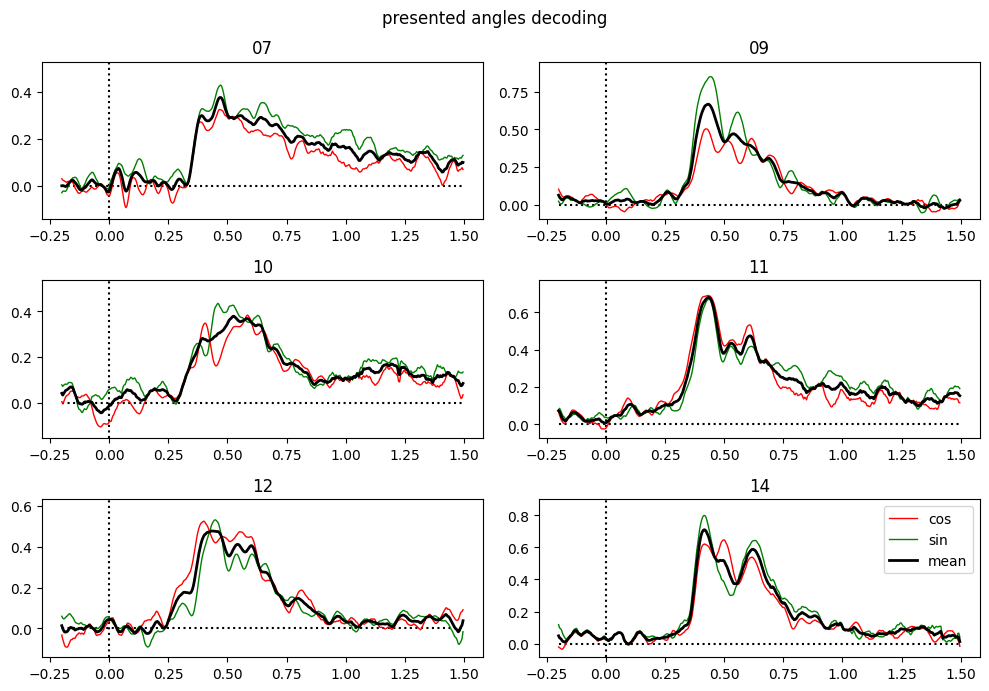

In [9]:
###### OPEN AND PLOT
##### PRESENTED ANGLES : viewed angles for all subjects

plt.figure(figsize = (10,9))
for i, sub in enumerate(SUBJS):
    
    epochs, metadata = load_epochs_metadata(sub, device)

    times = get_timearray(SW, tmin, tmax, epochs)

    idx_zero = np.abs(times - 0).argmin()
    idx_tmin = np.abs(times - tmin).argmin()
    idx_tmax = np.abs(times - tmax).argmin()


    alldat =[]

    plt.subplot(int(len(SUBJS)/2)+1, 2, i+1)
    
    datCos = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"presented_angles_Cos_{sub}.pkl", SW)
    datSin = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"presented_angles_Sin_{sub}.pkl", SW)
    border_max = max(np.array(datSin)[0,0,:])+0.1
    border_min = min(np.array(datCos)[0,0,:])-0.05
    plt.plot([times[0],times[-1]],[0,0], 'k:')
    plt.plot([0,0],[border_min,border_max], 'k:')
    
    dat = np.mean([datCos,datSin],0)
    alldat.append(np.array(dat).flatten())
    plt.plot(times, np.array(datCos)[0,0,:], 'red', linewidth=1, label = "cos")
    plt.plot(times, np.array(datSin)[0,0,:], 'green', linewidth=1, label = "sin")
    plt.plot(times, np.array(dat)[0,0,:], 'black', linewidth=2, label = "mean")
    plt.ylim([border_min,border_max])
    plt.title(sub)
plt.suptitle(f"presented angles decoding")
plt.tight_layout()
plt.legend()
plt.show()


There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 2 columns
Replacing existing metadata with 9 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))



There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 2 columns
Replacing existing metadata with 9 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))



There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 2 columns
Replacing existing metadata with 9 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))


... (2 outputs left out)


There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 2 columns
Replacing existing metadata with 9 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))



There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 2 columns
Replacing existing metadata with 9 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))


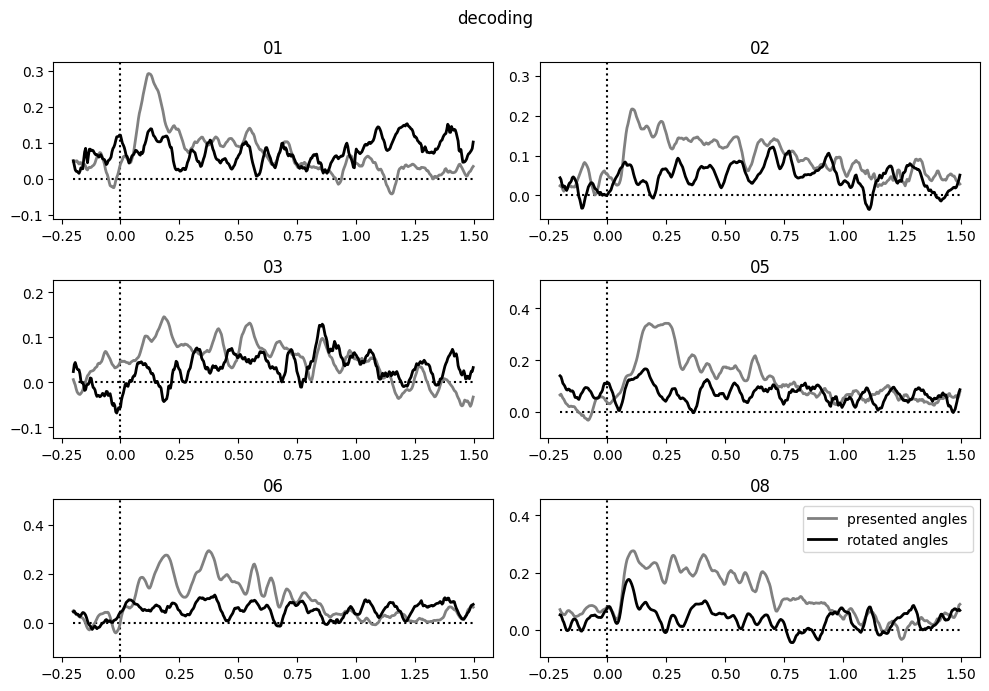

In [10]:
## PLOT PRESENTED AND ROTATED ANGLES FOR ALL SUBJECTS
# for all subjects before decoding changed


alldatres =[]
alldatrot = []

plt.figure(figsize = (10,9))
for i, sub in enumerate(SUBJS_NOT_GOOD):
    plt.subplot(int(len(SUBJS_NOT_GOOD)/2)+1, 2, i+1)
    
    epochs, metadata = load_epochs_metadata(sub, device)

    times = get_timearray(SW, tmin, tmax, epochs)
    idx_zero = np.abs(times - 0).argmin()
    idx_tmin = np.abs(times - tmin).argmin()
    idx_tmax = np.abs(times - tmax).argmin()
    
    datCospres = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"presented_angles_Cos_{sub}.pkl", SW)
    datSinpres = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"presented_angles_Sin_{sub}.pkl", SW)

    datCosrot = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"expected_angles_Cos_{sub}.pkl", SW)
    datSinrot = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"expected_angles_Sin_{sub}.pkl", SW)
    
    border_max = max(np.array(datSinpres)[0,0,:])+0.1
    border_min = min(np.array(datCospres)[0,0,:])-0.05
    plt.plot([times[0],times[-1]],[0,0], 'k:')
    plt.plot([0,0],[border_min,border_max], 'k:')
    
    datres = np.mean([datCospres,datSinpres],0)
    alldatres.append(np.array(datres).flatten())

    datrot = np.mean([datCosrot,datSinrot],0)
    alldatrot.append(np.array(datrot).flatten())

    
    plt.plot(times, np.array(datres)[0,0,:], 'grey', linewidth=2, label = "presented angles")
    plt.plot(times, np.array(datrot)[0,0,:], 'black', linewidth=2, label = "rotated angles")
    
    plt.ylim([border_min,border_max])
    plt.title(sub)
    
plt.suptitle(f"decoding")
plt.tight_layout()
plt.legend()
plt.savefig(derivative_root + f"decoding/plots/" + f"decoding_expected_vs_rotated_not_good_subjs.pdf")
plt.show()


There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 3 columns
Replacing existing metadata with 14 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))



There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 3 columns
Replacing existing metadata with 14 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))



There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 3 columns
Replacing existing metadata with 14 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))


... (2 outputs left out)


There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 3 columns
Replacing existing metadata with 14 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))



There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 2 columns
Replacing existing metadata with 13 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))


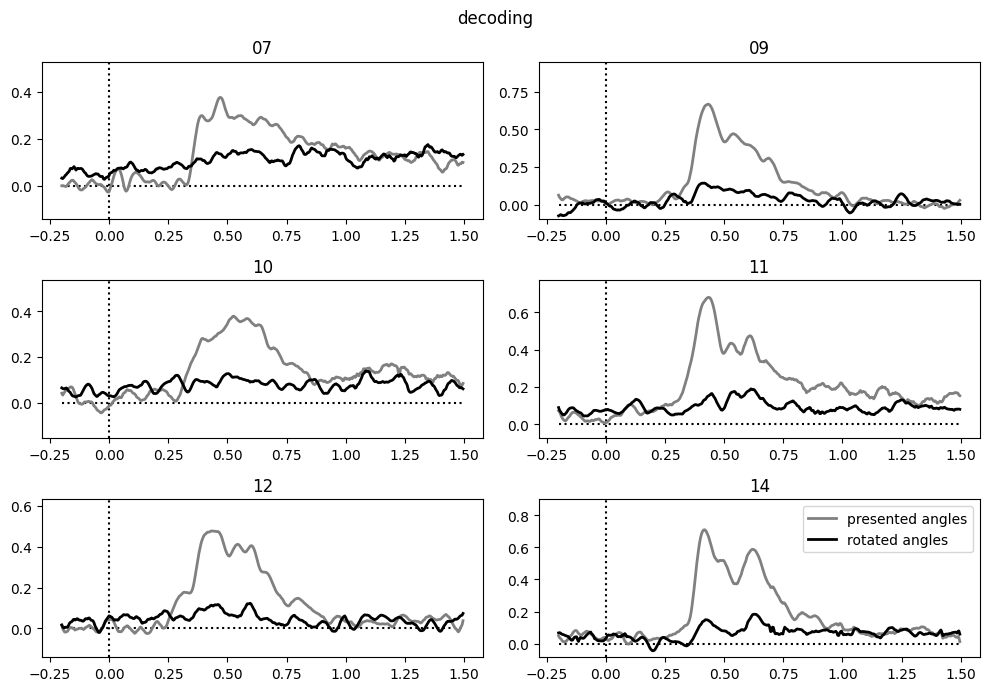

In [11]:
## PLOT PRESENTED AND ROTATED ANGLES FOR ALL SUBJECTS

alldatres =[]
alldatrot = []

plt.figure(figsize = (10,9))
for i, sub in enumerate(SUBJS):
    plt.subplot(int(len(SUBJS)/2)+1, 2, i+1)
    
    epochs, metadata = load_epochs_metadata(sub, device)

    times = get_timearray(SW, tmin, tmax, epochs)
    idx_zero = np.abs(times - 0).argmin()
    idx_tmin = np.abs(times - tmin).argmin()
    idx_tmax = np.abs(times - tmax).argmin()
    
    datCospres = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"presented_angles_Cos_{sub}.pkl", SW)
    datSinpres = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"presented_angles_Sin_{sub}.pkl", SW)

    datCosrot = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"expected_angles_Cos_{sub}.pkl", SW)
    datSinrot = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"expected_angles_Sin_{sub}.pkl", SW)
    
    border_max = max(np.array(datSinpres)[0,0,:])+0.1
    border_min = min(np.array(datCospres)[0,0,:])-0.05
    plt.plot([times[0],times[-1]],[0,0], 'k:')
    plt.plot([0,0],[border_min,border_max], 'k:')
    
    datres = np.mean([datCospres,datSinpres],0)
    alldatres.append(np.array(datres).flatten())

    datrot = np.mean([datCosrot,datSinrot],0)
    alldatrot.append(np.array(datrot).flatten())

    
    plt.plot(times, np.array(datres)[0,0,:], 'grey', linewidth=2, label = "presented angles")
    plt.plot(times, np.array(datrot)[0,0,:], 'black', linewidth=2, label = "rotated angles")
    
    plt.ylim([border_min,border_max])
    plt.title(sub)
    
plt.suptitle(f"decoding")
plt.tight_layout()
plt.legend()
plt.savefig(derivative_root + f"decoding/plots/" + f"decoding_expected_vs_rotated_good_subjs.pdf")
plt.show()

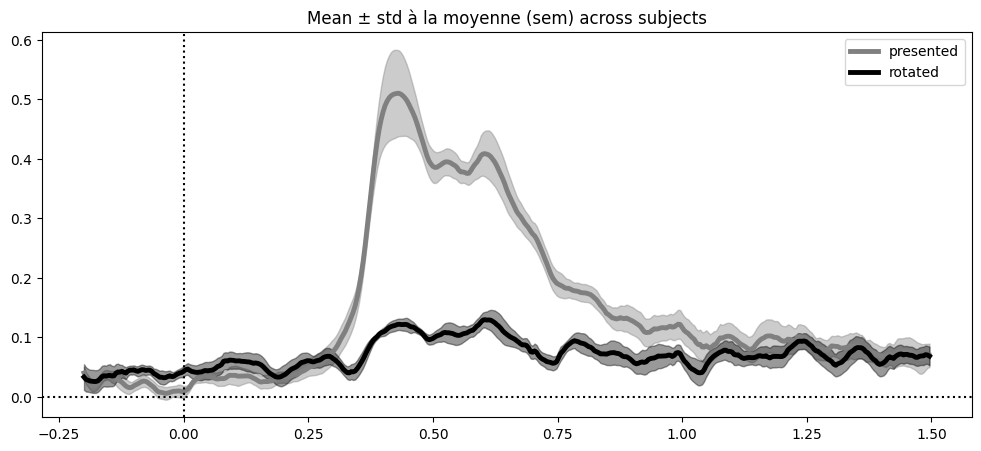

In [12]:
### PLOT OF THE MEAN DECODING FOR ALL SUBJECTS

np.random.seed(42)
alldatres =[]
alldatrot = []

# epochs, metadata = load_epochs_metadata("07", device)
# times = get_timearray(SW, tmin, tmax, epochs)

for i, sub in enumerate(SUBJS):    
    datCospres = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"presented_angles_Cos_{sub}.pkl", SW)
    datSinpres = open_decodingresults(derivative_root + "decoding/"+ f"sub-{sub}/" + f"presented_angles_Sin_{sub}.pkl", SW)

    datCosrot = open_decodingresults(derivative_root + "decoding/"+ f"sub-{sub}/" + f"expected_angles_Cos_{sub}.pkl", SW)
    datSinrot = open_decodingresults(derivative_root+ "decoding/"+ f"sub-{sub}/" + f"expected_angles_Sin_{sub}.pkl", SW)  
    
    datres = np.mean([datCospres,datSinpres],0)
    alldatres.append(np.array(datres).flatten())

    datrot = np.mean([datCosrot,datSinrot],0)
    alldatrot.append(np.array(datrot).flatten())
    
    
alldatres_arr = np.vstack(alldatres)
alldatrot_arr = np.vstack(alldatrot)

mean_res = np.mean(alldatres_arr, axis=0)
std_res  = np.std(alldatres_arr, axis=0)



mean_rot = np.mean(alldatrot_arr, axis=0)
std_rot  = np.std(alldatrot_arr, axis=0)

sem_res = std_res / np.sqrt(alldatres_arr.shape[0])
sem_rot = std_rot / np.sqrt(alldatrot_arr.shape[0])


plt.figure(figsize=(12,5))
plt.ylim(0.05, 0.6)
plt.xlim(-0.2,1.5)

plt.plot(times, mean_res, color='grey', linewidth=3.5, label='presented', alpha = 1)
plt.fill_between(times, mean_res - sem_res, mean_res + sem_res,
                 color='grey', alpha=0.4)

plt.plot(times, mean_rot, color='purple', linewidth=3.5, label='rotated', alpha = 1)
plt.fill_between(times, mean_rot - sem_rot, mean_rot + sem_rot,
                 color='purple', alpha=0.4)

plt.axhline(0, linestyle=':', color='k')
plt.axvline(0, linestyle=':', color='k')

plt.legend()
plt.title("Mean ± std à la moyenne (sem) across subjects")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/conf SBDM/figures/decoding.pdf")
plt.savefig(derivative_root + f"decoding/plots/" + f"decoding_expected_vs_mean_rotated_good_subjs.pdf")
plt.show()

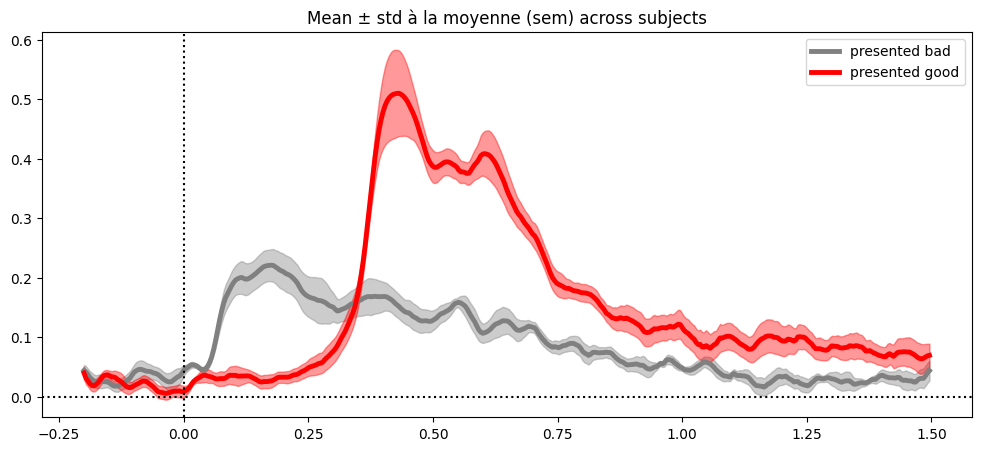

In [13]:
### PLOT OF THE MEAN DECODING FOR ALL SUBJECTS

np.random.seed(42)
alldatres =[]
alldatrot = []

# epochs, metadata = load_epochs_metadata("07", device)
# times = get_timearray(SW, tmin, tmax, epochs)

for i, sub in enumerate(SUBJS):    
    datCospres = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"presented_angles_Cos_{sub}.pkl", SW)
    datSinpres = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"presented_angles_Sin_{sub}.pkl", SW)

    datCosrot = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"expected_angles_Cos_{sub}.pkl", SW)
    datSinrot = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"expected_angles_Sin_{sub}.pkl", SW)  
    
    datres = np.mean([datCospres,datSinpres],0)
    alldatres.append(np.array(datres).flatten())

    datrot = np.mean([datCosrot,datSinrot],0)
    alldatrot.append(np.array(datrot).flatten())
    
    
alldatres_arr = np.vstack(alldatres)
alldatrot_arr = np.vstack(alldatrot)

mean_res = np.mean(alldatres_arr, axis=0)
std_res  = np.std(alldatres_arr, axis=0)



mean_rot = np.mean(alldatrot_arr, axis=0)
std_rot  = np.std(alldatrot_arr, axis=0)

sem_res = std_res / np.sqrt(alldatres_arr.shape[0])
sem_rot = std_rot / np.sqrt(alldatrot_arr.shape[0])







### PLOT OF THE MEAN DECODING FOR ALL SUBJECTS

alldatres2 =[]
alldatrot2 = []

# epochs, metadata = load_epochs_metadata("07", device)
# times = get_timearray(SW, tmin, tmax, epochs)

for i, sub in enumerate(SUBJS_NOT_GOOD):    
    datCospres = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"presented_angles_Cos_{sub}.pkl", SW)
    datSinpres = open_decodingresults(derivative_root + "decoding/"+ f"sub-{sub}/" + f"presented_angles_Sin_{sub}.pkl", SW)

    datCosrot = open_decodingresults(derivative_root + "decoding/"+ f"sub-{sub}/" + f"expected_angles_Cos_{sub}.pkl", SW)
    datSinrot = open_decodingresults(derivative_root+ "decoding/"+ f"sub-{sub}/" + f"expected_angles_Sin_{sub}.pkl", SW)  
    
    datres = np.mean([datCospres,datSinpres],0)
    alldatres2.append(np.array(datres).flatten())

    datrot = np.mean([datCosrot,datSinrot],0)
    alldatrot2.append(np.array(datrot).flatten())
    
    
alldatres_arr2 = np.vstack(alldatres2)
alldatrot_arr2 = np.vstack(alldatrot2)
mean_res2 = np.mean(alldatres_arr2, axis=0)
std_res2  = np.std(alldatres_arr2, axis=0)
mean_rot2 = np.mean(alldatrot_arr2, axis=0)
std_rot2  = np.std(alldatrot_arr2, axis=0)
sem_res2 = std_res2 / np.sqrt(alldatres_arr2.shape[0])
sem_rot2 = std_rot2 / np.sqrt(alldatrot_arr2.shape[0])




plt.figure(figsize=(12,5))

plt.plot(times, mean_res2, color='grey', linewidth=3.5, label='presented bad', alpha = 1)
plt.fill_between(times, mean_res2 - sem_res2, mean_res2 + sem_res2,
                 color='grey', alpha=0.4)

# plt.plot(times, mean_rot2, color='black', linewidth=3.5, label='rotated', alpha = 1)
# plt.fill_between(times, mean_rot2 - sem_rot2, mean_rot2 + sem_rot2,
#                  color='black', alpha=0.4)



plt.plot(times, mean_res, color='red', linewidth=3.5, label='presented good', alpha = 1)
plt.fill_between(times, mean_res - sem_res, mean_res + sem_res,
                 color='red', alpha=0.4)

# plt.plot(times, mean_rot, color='black', linewidth=3.5, label='rotated', alpha = 1)
# plt.fill_between(times, mean_rot - sem_rot, mean_rot + sem_rot,
#                  color='black', alpha=0.4)

plt.axhline(0, linestyle=':', color='k')
plt.axvline(0, linestyle=':', color='k')

plt.legend()
plt.title("Mean ± std à la moyenne (sem) across subjects")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/conf SBDM/figures/decoding.pdf")
plt.savefig(derivative_root + f"decoding/plots/" + f"decoding_presented_not_good_vs_good_subjs.pdf")
plt.show()

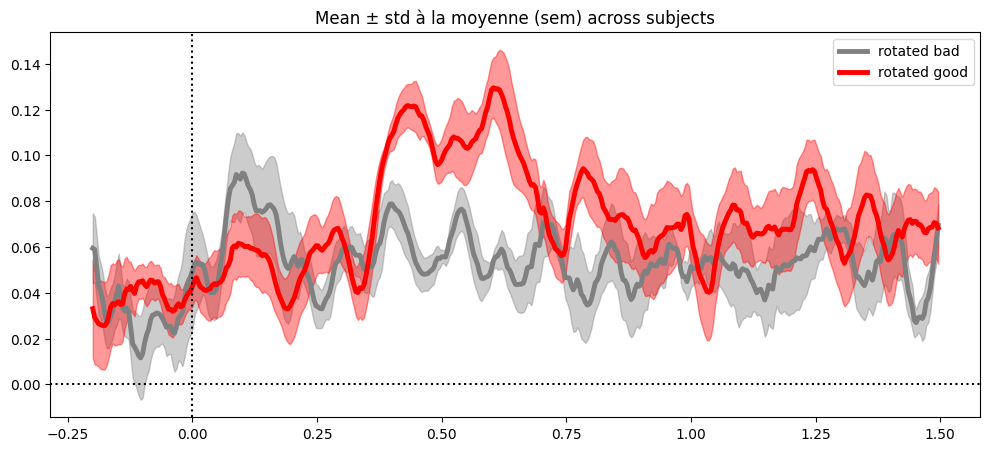

In [14]:
### PLOT OF THE MEAN DECODING FOR ALL SUBJECTS

np.random.seed(42)
alldatres =[]
alldatrot = []

# epochs, metadata = load_epochs_metadata("07", device)
# times = get_timearray(SW, tmin, tmax, epochs)

for i, sub in enumerate(SUBJS):    
    datCospres = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"presented_angles_Cos_{sub}.pkl", SW)
    datSinpres = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"presented_angles_Sin_{sub}.pkl", SW)

    datCosrot = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"expected_angles_Cos_{sub}.pkl", SW)
    datSinrot = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"expected_angles_Sin_{sub}.pkl", SW)  
    
    datres = np.mean([datCospres,datSinpres],0)
    alldatres.append(np.array(datres).flatten())

    datrot = np.mean([datCosrot,datSinrot],0)
    alldatrot.append(np.array(datrot).flatten())
    
    
alldatres_arr = np.vstack(alldatres)
alldatrot_arr = np.vstack(alldatrot)

mean_res = np.mean(alldatres_arr, axis=0)
std_res  = np.std(alldatres_arr, axis=0)



mean_rot = np.mean(alldatrot_arr, axis=0)
std_rot  = np.std(alldatrot_arr, axis=0)

sem_res = std_res / np.sqrt(alldatres_arr.shape[0])
sem_rot = std_rot / np.sqrt(alldatrot_arr.shape[0])







### PLOT OF THE MEAN DECODING FOR ALL SUBJECTS

alldatres2 =[]
alldatrot2 = []

# epochs, metadata = load_epochs_metadata("07", device)
# times = get_timearray(SW, tmin, tmax, epochs)

for i, sub in enumerate(SUBJS_NOT_GOOD):    
    datCospres = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"presented_angles_Cos_{sub}.pkl", SW)
    datSinpres = open_decodingresults(derivative_root + "decoding/"+ f"sub-{sub}/" + f"presented_angles_Sin_{sub}.pkl", SW)

    datCosrot = open_decodingresults(derivative_root + "decoding/"+ f"sub-{sub}/" + f"expected_angles_Cos_{sub}.pkl", SW)
    datSinrot = open_decodingresults(derivative_root+ "decoding/"+ f"sub-{sub}/" + f"expected_angles_Sin_{sub}.pkl", SW)  
    
    datres = np.mean([datCospres,datSinpres],0)
    alldatres2.append(np.array(datres).flatten())

    datrot = np.mean([datCosrot,datSinrot],0)
    alldatrot2.append(np.array(datrot).flatten())
    
    
alldatres_arr2 = np.vstack(alldatres2)
alldatrot_arr2 = np.vstack(alldatrot2)
mean_res2 = np.mean(alldatres_arr2, axis=0)
std_res2  = np.std(alldatres_arr2, axis=0)
mean_rot2 = np.mean(alldatrot_arr2, axis=0)
std_rot2  = np.std(alldatrot_arr2, axis=0)
sem_res2 = std_res2 / np.sqrt(alldatres_arr2.shape[0])
sem_rot2 = std_rot2 / np.sqrt(alldatrot_arr2.shape[0])




plt.figure(figsize=(12,5))

# plt.plot(times, mean_res2, color='grey', linewidth=3.5, label='presented bad', alpha = 1)
# plt.fill_between(times, mean_res2 - sem_res2, mean_res2 + sem_res2,
#                  color='grey', alpha=0.4)

plt.plot(times, mean_rot2, color='grey', linewidth=3.5, label='rotated bad', alpha = 1)
plt.fill_between(times, mean_rot2 - sem_rot2, mean_rot2 + sem_rot2,
                 color='grey', alpha=0.4)



# plt.plot(times, mean_res, color='grey', linewidth=3.5, label='presented good', alpha = 1)
# plt.fill_between(times, mean_res - sem_res, mean_res + sem_res,
#                  color='grey', alpha=0.4)

plt.plot(times, mean_rot, color='red', linewidth=3.5, label='rotated good', alpha = 1)
plt.fill_between(times, mean_rot - sem_rot, mean_rot + sem_rot,
                 color='red', alpha=0.4)

plt.axhline(0, linestyle=':', color='k')
plt.axvline(0, linestyle=':', color='k')

plt.legend()
plt.title("Mean ± std à la moyenne (sem) across subjects")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/conf SBDM/figures/decoding.pdf")
plt.savefig(derivative_root + f"decoding/plots/" + f"decoding_rotated_not_good_vs_good_subjs.pdf")
plt.show()

- utiliser test_id : pour split scores faibles, rotations
- faire autre decoding pour variabes catégoritielles (SVM...)
- adapter les rotations avec les résultats des fit

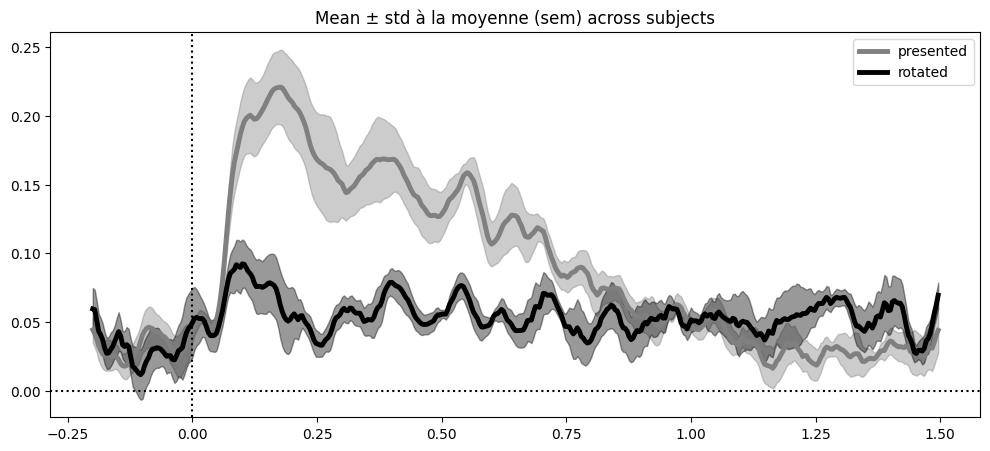

In [15]:
### PLOT OF THE MEAN DECODING FOR ALL SUBJECTS

np.random.seed(42)
alldatres =[]
alldatrot = []

# epochs, metadata = load_epochs_metadata("07", device)
# times = get_timearray(SW, tmin, tmax, epochs)

for i, sub in enumerate(SUBJS_NOT_GOOD):    
    datCospres = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"presented_angles_Cos_{sub}.pkl", SW)
    datSinpres = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"presented_angles_Sin_{sub}.pkl", SW)

    datCosrot = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"expected_angles_Cos_{sub}.pkl", SW)
    datSinrot = open_decodingresults(derivative_root + "decoding/" + f"sub-{sub}/" + f"expected_angles_Sin_{sub}.pkl", SW)  
    
    datres = np.mean([datCospres,datSinpres],0)
    alldatres.append(np.array(datres).flatten())

    datrot = np.mean([datCosrot,datSinrot],0)
    alldatrot.append(np.array(datrot).flatten())
    
    
alldatres_arr = np.vstack(alldatres)
alldatrot_arr = np.vstack(alldatrot)

mean_res = np.mean(alldatres_arr, axis=0)
std_res  = np.std(alldatres_arr, axis=0)



mean_rot = np.mean(alldatrot_arr, axis=0)
std_rot  = np.std(alldatrot_arr, axis=0)

sem_res = std_res / np.sqrt(alldatres_arr.shape[0])
sem_rot = std_rot / np.sqrt(alldatrot_arr.shape[0])


plt.figure(figsize=(12,5))
plt.ylim(0.05, 0.6)
plt.xlim(-0.2,1.5)

plt.plot(times, mean_res, color='grey', linewidth=3.5, label='presented', alpha = 1)
plt.fill_between(times, mean_res - sem_res, mean_res + sem_res,
                 color='grey', alpha=0.4)

plt.plot(times, mean_rot, color='purple', linewidth=3.5, label='rotated', alpha = 1)
plt.fill_between(times, mean_rot - sem_rot, mean_rot + sem_rot,
                 color='purple', alpha=0.4)

plt.axhline(0, linestyle=':', color='k')
plt.axvline(0, linestyle=':', color='k')

plt.legend()
plt.title("Mean ± std à la moyenne (sem) across subjects")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/conf SBDM/figures/decoding.pdf")
plt.savefig(derivative_root + f"decoding/plots/" + f"decoding_expected_vs_mean_rotated_not_good_subjs.pdf")
plt.show()

# **decoding of fitted rotation**

In [16]:
metadata

,index,event_name,stim_color,presented_angles_rad,block,rotation_in_radian,rotation_in_degrees,fitted_value_deg,expected_angles,expected_angles_rad,presented_angles,fitted_expected_angles,fitted_expected_angles_rad
0,0,Stim/S1,blue,3.038372,1,2.123890,-45.0,-35.035297,129.085891,2.252974,174.085891,139.050594,2.426891
1,1,Stim/S2,blue,0.204355,1,2.123890,-45.0,-35.035297,146.708677,2.560549,191.708677,156.673380,2.734466
2,2,Stim/S3,green,2.866158,1,0.000000,0.0,0.000000,164.218773,2.866158,164.218773,164.218773,2.866158
3,3,Stim/S4,blue,2.992359,1,2.123890,-45.0,-35.035297,126.449519,2.206960,171.449519,136.414222,2.380877
4,4,Stim/S5,blue,0.104823,1,2.123890,-45.0,-35.035297,141.005917,2.461018,186.005917,150.970621,2.634934
...,...,...,...,...,...,...,...,...,...,...,...,...,...
1435,1435,Stim/S1,blue,2.408245,10,2.123890,-45.0,-35.035297,92.982263,1.622847,137.982263,102.946966,1.796764
1436,1436,Stim/S2,blue,1.821186,10,2.123890,-45.0,-35.035297,59.346296,1.035788,104.346296,69.310999,1.209705
1437,1437,Stim/S3,green,1.234621,10,0.000000,0.0,0.000000,70.738591,1.234621,70.738591,70.738591,1.234621
1438,1438,Stim/S4,blue,2.054883,10,2.123890,-45.0,-35.035297,72.736125,1.269485,117.736125,82.700829,1.443402


In [17]:
## PLOT PRESENTED AND ROTATED ANGLES FOR ALL SUBJECTS
sub = "14" 


alldatres =[]
alldatrot = []
alldatfit = []

plt.figure(figsize = (10,9))
epochs, metadata = load_epochs_metadata(sub, device)
times = get_timearray(SW, tmin, tmax, epochs)
idx_zero = np.abs(times - 0).argmin()
idx_tmin = np.abs(times - tmin).argmin()
idx_tmax = np.abs(times - tmax).argmin()

datCospres = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"presented_angles_Cos_{sub}.pkl", SW)
datSinpres = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"presented_angles_Sin_{sub}.pkl", SW)
datCosrot = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"expected_angles_Cos_{sub}.pkl", SW)
datSinrot = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"expected_angles_Sin_{sub}.pkl", SW)

datCosfit = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"fitted_expected_angles_Cos_{sub}.pkl", SW)
datSinfit = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"fitted_expected_angles_Sin_{sub}.pkl", SW)

border_max = max(np.array(datSinpres)[0,0,:])+0.1
border_min = min(np.array(datCospres)[0,0,:])-0.05
plt.plot([times[0],times[-1]],[0,0], 'k:')
plt.plot([0,0],[border_min,border_max], 'k:')

datfit = np.mean([datCosfit, datSinfit], 0)
alldatfit.append(np.array(datfit).flatten())

datres = np.mean([datCospres,datSinpres],0)
alldatres.append(np.array(datres).flatten())
datrot = np.mean([datCosrot,datSinrot],0)
alldatrot.append(np.array(datrot).flatten())

plt.plot(times, np.array(datres)[0,0,:], 'grey', linewidth=2, label = "presented angles")
plt.plot(times, np.array(datrot)[0,0,:], 'black', linewidth=2, label = "rotated angles")
plt.plot(times, np.array(datfit)[0,0,:], 'red', linewidth=2, label = "fitted expected angles")

plt.ylim([border_min,border_max])
plt.title(sub)
    
plt.tight_layout()
plt.legend()
plt.savefig(derivative_root + f"decoding/plots/" + f"decoding_expected_vs_rotated_vs_fitted_subj{sub}.pdf")
plt.show()

FileNotFoundError: File does not exist: "/Volumes/My Passport/Data/derivatives/mne-bids-pipeline/sub-/meg/sub-_task-FRINT_proc-clean_epo.fif"

<Figure size 1000x900 with 0 Axes>


There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 3 columns
Replacing existing metadata with 14 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))



There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 3 columns
Replacing existing metadata with 14 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))



There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 3 columns
Replacing existing metadata with 14 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))


... (2 outputs left out)


There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 3 columns
Replacing existing metadata with 14 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))



There are 
n_trial = 1440 epochs, 
n_channels = 328 channels, 
n_times = 426 time points
Replacing existing metadata with 2 columns
Replacing existing metadata with 13 columns


/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:128: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  epochs.get_data().shape
/var/folders/mw/n57xkpsj1tj5zlvd4f4hyj1c0000gp/T/ipykernel_15804/2126395479.py:129: FutureWarning: The current default of copy=False will change to copy=True in 1.7. Set the value of copy explicitly to avoid this warning
  print("\nThere are \nn_trial = {} epochs, \nn_channels = {} channels, \nn_times = {} time points".format(*epochs.get_data().shape))


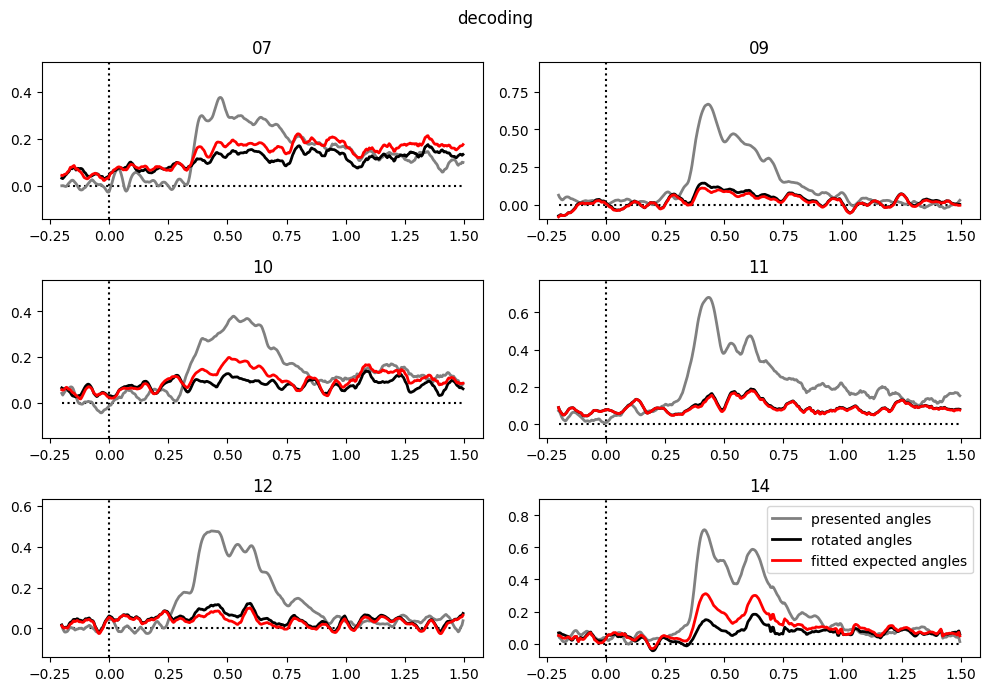

In [19]:
## PLOT PRESENTED AND ROTATED ANGLES FOR ALL SUBJECTS

alldatres =[]
alldatrot = []
alldatfit = []

plt.figure(figsize = (10,9))
for i, sub in enumerate(SUBJS):
    plt.subplot(int(len(SUBJS)/2)+1, 2, i+1)
    
    epochs, metadata = load_epochs_metadata(sub, device)

    times = get_timearray(SW, tmin, tmax, epochs)
    idx_zero = np.abs(times - 0).argmin()
    idx_tmin = np.abs(times - tmin).argmin()
    idx_tmax = np.abs(times - tmax).argmin()
    
    datCospres = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"presented_angles_Cos_{sub}.pkl", SW)
    datSinpres = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"presented_angles_Sin_{sub}.pkl", SW)

    datCosrot = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"expected_angles_Cos_{sub}.pkl", SW)
    datSinrot = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"expected_angles_Sin_{sub}.pkl", SW)
    
    datCosfit = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"fitted_expected_angles_Cos_{sub}.pkl", SW)
    datSinfit = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"fitted_expected_angles_Sin_{sub}.pkl", SW)        
    
    border_max = max(np.array(datSinpres)[0,0,:])+0.1
    border_min = min(np.array(datCospres)[0,0,:])-0.05
    plt.plot([times[0],times[-1]],[0,0], 'k:')
    plt.plot([0,0],[border_min,border_max], 'k:')
    
    datres = np.mean([datCospres,datSinpres],0)
    alldatres.append(np.array(datres).flatten())

    datrot = np.mean([datCosrot,datSinrot],0)
    alldatrot.append(np.array(datrot).flatten())

    datfit = np.mean([datCosfit, datSinfit], 0)
    alldatfit.append(np.array(datfit).flatten())



    plt.plot(times, np.array(datres)[0,0,:], 'grey', linewidth=2, label = "presented angles")
    plt.plot(times, np.array(datrot)[0,0,:], 'black', linewidth=2, label = "rotated angles")
    plt.plot(times, np.array(datfit)[0,0,:], 'red', linewidth=2, label = "fitted expected angles")

    
    plt.ylim([border_min,border_max])
    plt.title(sub)
    
plt.suptitle(f"decoding")
plt.tight_layout()
plt.legend()
plt.savefig(derivative_root + f"decoding/plots/" + f"decoding_expected_vs_rotated_good_subjs.pdf")
plt.show()

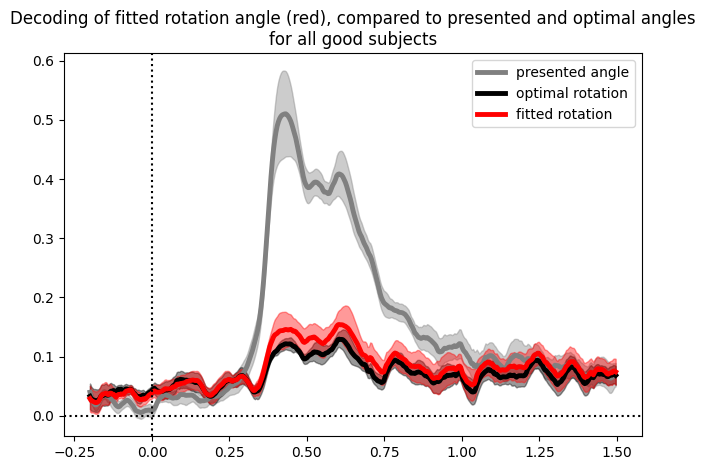

In [18]:
## PLOT PRESENTED AND ROTATED ANGLES FOR ALL SUBJECTS
np.random.seed(42)
alldatres =[]
alldatrot = []
alldatfit = []


for i, sub in enumerate(SUBJS):
    
    datCospres = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"presented_angles_Cos_{sub}.pkl", SW)
    datSinpres = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"presented_angles_Sin_{sub}.pkl", SW)

    datCosrot = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"expected_angles_Cos_{sub}.pkl", SW)
    datSinrot = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"expected_angles_Sin_{sub}.pkl", SW)
    
    datCosfit = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"fitted_expected_angles_Cos_{sub}.pkl", SW)
    datSinfit = open_decodingresults(derivative_root + f"decoding/sub-{sub}/" + f"fitted_expected_angles_Sin_{sub}.pkl", SW)        
    
    datres = np.mean([datCospres,datSinpres],0)
    alldatres.append(np.array(datres).flatten())
    datrot = np.mean([datCosrot,datSinrot],0)
    alldatrot.append(np.array(datrot).flatten())
    datfit = np.mean([datCosfit, datSinfit], 0)
    alldatfit.append(np.array(datfit).flatten())
    
alldatres_arr = np.vstack(alldatres)
alldatrot_arr = np.vstack(alldatrot)
alldatfit_arr = np.vstack(alldatfit)


mean_res = np.mean(alldatres_arr, axis=0)
std_res  = np.std(alldatres_arr, axis=0)

mean_rot = np.mean(alldatrot_arr, axis=0)
std_rot  = np.std(alldatrot_arr, axis=0)

mean_fit = np.mean(alldatfit_arr, axis=0)
std_fit  = np.std(alldatfit_arr, axis=0)

sem_res = std_res / np.sqrt(alldatres_arr.shape[0])
sem_rot = std_rot / np.sqrt(alldatrot_arr.shape[0])
sem_fit = std_fit / np.sqrt(alldatfit_arr.shape[0])





border_max = max(np.array(datSinpres)[0,0,:])+0.1
border_min = min(np.array(datCospres)[0,0,:])-0.05
# plt.plot([times[0],times[-1]],[0,0], 'k:')
# plt.plot([0,0],[border_min,border_max], 'k:')


plt.figure(figsize=(12,5))
plt.ylim(0.05, 0.6)
plt.xlim(-0.2,1.5)
plt.plot(times, mean_res, color='grey', linewidth=3.5, label='presented angle', alpha = 1)
plt.fill_between(times, mean_res - sem_res, mean_res + sem_res,
                 color='grey', alpha=0.4)

plt.plot(times, mean_rot, color='black', linewidth=3.5, label='optimal rotation', alpha = 1)
plt.fill_between(times, mean_rot - sem_rot, mean_rot + sem_rot,
                 color='black', alpha=0.4)

plt.plot(times, mean_fit, color='red', linewidth=3.5, label='fitted rotation', alpha = 1)
plt.fill_between(times, mean_fit - sem_fit, mean_fit + sem_fit,
                 color='red', alpha=0.4)



plt.axhline(0, linestyle=':', color='k')
plt.axvline(0, linestyle=':', color='k')

plt.legend()

plt.title("Decoding of fitted rotation angle (red), compared to presented and optimal angles\nfor all good subjects")
# plt.savefig("/Users/elodiehusson/Desktop/Projet/conf SBDM/figures/decoding.pdf")
plt.savefig(derivative_root + f"decoding/plots/" + f"decoding_fitted_angles_vs_presented_and_expected.pdf")
plt.tight_layout()
plt.show()